# Лабораторная работа №4
**Тема:** Диагностика ошибок в данных, проверка статистических гипотез.

**Цель работы:** освоить методы диагностики ошибок в данных и корректирующих процедур, а также провести статистический анализ показателей новорождённых.

**Задачи работы:**
1. Провести диагностику ошибок в наборе данных.
2. Классифицировать обнаруженные ошибки.
3. Применить корректирующие процедуры.
4. Оценить влияние ошибок на результаты анализа.
5. Задокументировать этапы диагностики и коррекции.

---
### Этап 1. Загрузка данных и первичное знакомство с датасетом
Импортируем необходимые библиотеки для работы с таблицами, математическими расчетами и графиками. Загрузим файл `Пренатальная диагностика.xlsx` и посмотрим на первые и последние строки таблицы, чтобы понять её структуру.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Настраиваем отображение графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# Загружаем датасет
df_raw = pd.read_excel('Пренатальная диагностика.xlsx')

print("Первые 5 строк таблицы:")
display(df_raw.head())

print("\nПоследние 10 строк таблицы:")
display(df_raw.tail(10))


Первые 5 строк таблицы:


,vozrast,gr-dni,ctr,nt,rost,ves,"pol(1-м, 0-д)"
0,18,70,61,1.3,48,3100,0
1,22,72,50,0.9,50,3400,0
2,29,73,45,0.9,53,3500,1
3,28,74,47,1.1,50,3490,1
4,31,74,46,1.3,53,3590,0



Последние 10 строк таблицы:


,vozrast,gr-dni,ctr,nt,rost,ves,"pol(1-м, 0-д)"
1040,24,104,84,0.4,52,3480,1
1041,26,105,80,1.0,50,2980,1
1042,24,105,81,1.1,52,3160,1
1043,26,105,84,0.4,50,3430,1
1044,28,105,78,0.8,53,3510,1
1045,27,105,83,1.4,56,4650,1
1046,30,105,80,0.9,51,3500,1
1047,21,107,84,1.9,52,3370,0
1048,18,107,82,1.7,48,3110,0
1049,28,108,78,0.8,48,2940,0


**Вывод по Этапу 1:**
Файл `Пренатальная диагностика.xlsx` успешно загружен в DataFrame. Первичный визуальный осмотр крайних записей показал, что таблица состоит из **1050 наблюдений** (индексы от `0` до `1049`) и **7 признаков**:
* `vozrast` — возраст беременной во время проведения УЗИ (в годах);
* `gr-dni` — срок гестации / беременности (в днях);
* `ctr` — копчико-теменной размер плода (КТР);
* `nt` — толщина воротникового пространства (ТВП);
* `rost` — рост новорождённого при рождении (в см);
* `ves` — масса тела новорождённого при рождении (в граммах);
* `pol(1-м, 0-д)` — бинарный признак пола ребёнка (`1` — мальчик, `0` — девочка).

Нарушений структуры на границах таблицы (посторонних текстовых примечаний, сдвигов столбцов или «битых» заголовков) не зафиксировано. При этом название столбца `pol(1-м, 0-д)` содержит пробелы и спецсимволы, поэтому на следующем этапе его целесообразно переименовать в `pol` для удобства работы. Данные готовы к проведению комплексной диагностики ошибок.


### Этап 2. Диагностика ошибок в наборе данных
Перед проведением статистического анализа необходимо проверить качество исходных данных.
На этом этапе мы:
1. Переименуем столбец `pol(1-м, 0-д)` в `pol` для удобства обращения к нему в коде.
2. Проверим типы данных (все ли столбцы распознаны как числа, нет ли скрытых текстовых символов).
3. Проверим наличие пропущенных значений (`NaN`).
4. Проверим таблицу на наличие полных дубликатов (строк, где абсолютно все 7 параметров совпадают).
5. Проверим данные на логические противоречия (например, отрицательный вес или коды пола, отличные от 0 и 1).


In [2]:
# Создадим рабочую копию датасета и переименуем колонку с полом
df_raw = df_raw.rename(columns={'pol(1-м, 0-д)': 'pol'})

print("1. Информация о типах данных и непустых значениях:")
df_raw.info()

print("\n2. Количество пропущенных значений (NaN) в каждом столбце:")
print(df_raw.isnull().sum())

# 3. Поиск полных дубликатов строк
duplicates_count = df_raw.duplicated().sum()
print(f"\n3. Количество полных дубликатов строк: {duplicates_count}")

if duplicates_count > 0:
    print("\nПримеры дублирующихся записей (включая оригиналы):")
    display(df_raw[df_raw.duplicated(keep=False)].sort_values(by=['vozrast', 'gr-dni', 'ves']).head(10))

# 4. Проверка уникальных значений в столбце пола и минимальных значений
print("\n4. Уникальные значения в столбце 'pol':", df_raw['pol'].unique())


1. Информация о типах данных и непустых значениях:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1050 entries, 0 to 1049
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   vozrast  1050 non-null   int64  
 1   gr-dni   1050 non-null   int64  
 2   ctr      1050 non-null   int64  
 3   nt       1050 non-null   float64
 4   rost     1050 non-null   int64  
 5   ves      1050 non-null   int64  
 6   pol      1050 non-null   int64  
dtypes: float64(1), int64(6)
memory usage: 57.6 KB

2. Количество пропущенных значений (NaN) в каждом столбце:
vozrast    0
gr-dni     0
ctr        0
nt         0
rost       0
ves        0
pol        0
dtype: int64

3. Количество полных дубликатов строк: 26

Примеры дублирующихся записей (включая оригиналы):


,vozrast,gr-dni,ctr,nt,rost,ves,pol
307,20,85,58,1.6,50,3150,1
308,20,85,58,1.6,50,3150,1
936,22,97,74,1.5,50,3360,0
937,22,97,74,1.5,50,3360,0
716,23,92,74,1.6,51,3310,0
727,23,92,74,1.6,51,3310,0
147,24,82,56,1.4,53,3840,1
161,24,82,56,1.4,53,3840,1
508,24,88,60,1.3,54,3830,1
510,24,88,60,1.3,54,3830,1



4. Уникальные значения в столбце 'pol': [0 1]


**Вывод по Этапу 2 (Результаты диагностики и классификация ошибок):**
1. **Типы данных и пропуски:** Все 7 столбцов имеют корректные числовые типы данных (`int64` для целочисленных признаков и `float64` для толщины воротникового пространства `nt`). Пропущенных значений (`NaN`) в таблице нет (во всех столбцах ровно по 1050 непустых значений).
2. **Логический контроль кодировки:** В столбце `pol` присутствуют только допустимые бинарные значения `0` и `1`, посторонних символов или опечаток при кодировании пола не допущено.
3. **Обнаруженные ошибки и их классификация:** В ходе проверки выявлено **26 полных дубликатов строк**. Анализ индексов показывает, что многие дублирующиеся записи расположены в таблице друг за другом (например, строки `307` и `308`, `936` и `937`) или на небольшом удалении (`508` и `510`). Полное совпадение сразу по 7 независимым медицинским и антропометрическим параметрам указывает на то, что это **техническая (случайная) ошибка регистрации данных** — повторный ввод одних и тех же карт пациентов оператором или сбой при объединении таблиц.


---
### Этап 3. Применение корректирующих процедур и базовые расчеты
Для устранения обнаруженных технических ошибок (дублирования записей) применим корректирующую процедуру — удаление полных дубликатов с помощью метода `drop_duplicates()`. Исходный датасет сохраним в переменной `df_raw` для последующей оценки влияния ошибок на результаты анализа, а очищенный запишем в переменную `df`.

После очистки выполним первые расчетные задачи:
1. Определим точное количество родившихся мальчиков (`1`) и девочек (`0`), а также сравним эти цифры с неочищенными данными.
2. Добавим новый столбец **ИМТ** (индекс массы тела новорождённого), который рассчитывается по формуле:
$$ИМТ = \frac{m}{h^2}$$
где $m$ — масса тела в килограммах (`ves / 1000`), а $h$ — рост в метрах (`rost / 100`).


In [3]:
# 1. Применяем корректирующую процедуру: удаляем полные дубликаты
df = df_raw.drop_duplicates().reset_index(drop=True)

print(f"Размер таблицы ДО очистки: {len(df_raw)} строк")
print(f"Размер таблицы ПОСЛЕ очистки: {len(df)} строк")
print(f"Удалено дубликатов: {len(df_raw) - len(df)}")

# 2. Считаем количество мальчиков (1) и девочек (0) до и после очистки
boys_raw = (df_raw['pol'] == 1).sum()
girls_raw = (df_raw['pol'] == 0).sum()

boys_clean = (df['pol'] == 1).sum()
girls_clean = (df['pol'] == 0).sum()

print("\nРаспределение по полу:")
print(f"Мальчики (1): {boys_clean} чел. (до очистки было {boys_raw}, дубликатов среди них: {boys_raw - boys_clean})")
print(f"Девочки (0):  {girls_clean} чел. (до очистки было {girls_raw}, дубликатов среди них: {girls_raw - girls_clean})")

# 3. Добавляем столбец ИМТ (переводим граммы в кг, а сантиметры в метры)
df_raw['IMT'] = (df_raw['ves'] / 1000) / ((df_raw['rost'] / 100) ** 2)
df['IMT'] = (df['ves'] / 1000) / ((df['rost'] / 100) ** 2)

print("\nПервые 5 строк очищенной таблицы с новым столбцом IMT:")
display(df.head())


Размер таблицы ДО очистки: 1050 строк
Размер таблицы ПОСЛЕ очистки: 1024 строк
Удалено дубликатов: 26

Распределение по полу:
Мальчики (1): 560 чел. (до очистки было 577, дубликатов среди них: 17)
Девочки (0):  464 чел. (до очистки было 473, дубликатов среди них: 9)

Первые 5 строк очищенной таблицы с новым столбцом IMT:


,vozrast,gr-dni,ctr,nt,rost,ves,pol,IMT
0,18,70,61,1.3,48,3100,0,13.454861
1,22,72,50,0.9,50,3400,0,13.600000
2,29,73,45,0.9,53,3500,1,12.459950
3,28,74,47,1.1,50,3490,1,13.960000
4,31,74,46,1.3,53,3590,0,12.780349


**Вывод по Этапу 3:**
1. **Результаты корректирующей процедуры:** Из исходного набора данных (1050 строк) было удалено 26 полных дубликатов. Итоговый объем очищенной выборки составил **1024 уникальных наблюдения**.
2. **Распределение новорождённых по полу (оценка влияния ошибок):**
   * В очищенном датасете родилось **560 мальчиков** (54,7%) и **464 девочки** (45,3%).
   * В исходном («грязном») датасете числилось **577 мальчиков** и **473 девочки**. Таким образом, наличие дубликатов искусственно завышало численность мальчиков на 17 записей, а девочек — на 9 записей.
3. **Добавление признака ИМТ:** Для каждого новорождённого успешно рассчитан индекс массы тела (`IMT`, $\text{кг/м}^2$). Судя по первым строкам, значения находятся в диапазоне около 12,4–14,0 $\text{кг/м}^2$, что соответствует физиологической норме для новорождённых детей.


---
### Этап 4. Расчет числовых характеристик и диагностика выбросов (аномалий)
Рассчитаем основные описательные статистики для всех количественных показателей (`vozrast`, `gr-dni`, `ctr`, `nt`, `rost`, `ves`, `IMT`):
* **Минимум (`min`) и максимум (`max`)** — крайние значения признака;
* **Размах (`range`)** — разность между максимумом и минимумом ($\max - \min$);
* **Среднее арифметическое (`mean`)** и **медиана (`median` / 50%-й перцентиль)** — меры центральной тенденции;
* **Мода (`mode`)** — наиболее часто встречающееся значение;
* **Стандартное отклонение (`std`)**, **дисперсия (`var`)** и **межквартильный размах (`IQR` = $Q_3 - Q_1$)** — меры разброса.

Дополнительно проведем диагностику экстремальных значений (выбросов) по правилу Тьюки (границы $[Q_1 - 1.5 \cdot IQR; Q_3 + 1.5 \cdot IQR]$) и проверим, как удаление дубликатов повлияло на средние значения показателей.


In [4]:
# Список количественных признаков (без бинарного столбца пола)
num_cols = ['vozrast', 'gr-dni', 'ctr', 'nt', 'rost', 'ves', 'IMT']

# 1. Собираем таблицу числовых характеристик (всё считается сразу для всех столбцов)
desc = df[num_cols].describe().T
desc['range'] = desc['max'] - desc['min']
desc['median'] = df[num_cols].median()
desc['mode'] = df[num_cols].mode().iloc[0]
desc['var'] = df[num_cols].var()
desc['IQR'] = desc['75%'] - desc['25%']

stats_table = desc[['min', 'max', 'range', 'mean', 'median', 'mode', 'std', 'var', '25%', '75%', 'IQR']]
stats_table.columns = ['Минимум', 'Максимум', 'Размах', 'Среднее', 'Медиана', 'Мода', 'Ст. откл.', 'Дисперсия', 'Q1 (25%)', 'Q3 (75%)', 'IQR']

print("1. Числовые характеристики показателей (очищенные данные, N = 1024):")
display(stats_table.round(3))

# 2. Сравним средние значения ДО и ПОСЛЕ удаления дубликатов
comparison_means = pd.DataFrame({
    'Среднее (ДО очистки)': df_raw[num_cols].mean(),
    'Среднее (ПОСЛЕ очистки)': df[num_cols].mean(),
    'Разница': (df[num_cols].mean() - df_raw[num_cols].mean()).abs()
})
print("\n2. Влияние дубликатов на средние значения показателей:")
display(comparison_means.round(4))

# 3. Диагностика статистических выбросов по правилу 1.5 * IQR
low_bounds = desc['25%'] - 1.5 * desc['IQR']
high_bounds = desc['75%'] + 1.5 * desc['IQR']
outliers_count = ((df[num_cols] < low_bounds) | (df[num_cols] > high_bounds)).sum()

outliers_table = pd.DataFrame({
    'Нижняя граница нормы': low_bounds.round(2),
    'Верхняя граница нормы': high_bounds.round(2),
    'Количество выбросов (шт.)': outliers_count
})
print("\n3. Диагностика статистических выбросов (по правилу 1.5 * IQR):")
display(outliers_table)


1. Числовые характеристики показателей (очищенные данные, N = 1024):


,Минимум,Максимум,Размах,Среднее,Медиана,Мода,Ст. откл.,Дисперсия,Q1 (25%),Q3 (75%),IQR
vozrast,16.000,45.000,29.000,28.696,28.0,27.000,5.425,29.434,25.000,33.000,8.000
gr-dni,70.000,108.000,38.000,88.812,88.0,87.000,6.327,40.028,84.000,93.000,9.000
ctr,45.000,85.000,40.000,64.164,64.0,66.000,10.472,109.662,56.000,72.000,16.000
nt,0.300,2.800,2.500,1.338,1.3,1.100,0.398,0.158,1.100,1.600,0.500
rost,45.000,60.000,15.000,51.701,52.0,52.000,2.092,4.378,50.000,53.000,3.000
ves,2410.000,5040.000,2630.000,3434.412,3430.0,3400.000,401.723,161381.277,3147.500,3700.000,552.500
IMT,8.686,18.117,9.431,12.823,12.8,12.574,1.022,1.045,12.104,13.409,1.305



2. Влияние дубликатов на средние значения показателей:


,Среднее (ДО очистки),Среднее (ПОСЛЕ очистки),Разница
vozrast,28.6819,28.6963,0.0144
gr-dni,88.7648,88.8115,0.0468
ctr,64.1257,64.1641,0.0383
nt,1.3373,1.3378,0.0005
rost,51.6981,51.7012,0.0031
ves,3435.7790,3434.4121,1.3669
IMT,12.8299,12.8227,0.0072



3. Диагностика статистических выбросов (по правилу 1.5 * IQR):


,Нижняя граница нормы,Верхняя граница нормы,Количество выбросов (шт.)
vozrast,13.00,45.00,0
gr-dni,70.50,106.50,4
ctr,32.00,96.00,0
nt,0.35,2.35,15
rost,45.50,57.50,8
ves,2318.75,4528.75,10
IMT,10.15,15.37,13


**Вывод по Этапу 4:**
1. **Основные характеристики:** Средний возраст рожениц составил **28,7 лет** (от 16 до 45 лет). УЗИ проводилось в среднем на **89-й день** беременности. Средний рост новорождённых равен **51,7 см** (медиана — 52 см), средний вес — **3434,4 г** (медиана — 3430 г), а средний ИМТ — **12,82**. У всех признаков среднее значение и медиана почти совпадают, значит, сильных перекосов в данных нет.
2. **Влияние дубликатов:** Из-за 26 дубликатов средний вес в исходной таблице был завышен на **1,37 г** (3435,78 г до очистки против 3434,41 г после), так как среди повторов было больше мальчиков. На остальные показатели дубликаты почти не повлияли (разница в сотых долях).
3. **Проверка на выбросы:** По правилу $1.5 \cdot IQR$ нашлись единичные крайние значения (например, 10 по весу и 8 по росту). Но если посмотреть на минимум и максимум (вес от 2410 до 5040 г, рост от 45 до 60 см), видно, что это не ошибки ввода, а реальные случаи рождения маленьких или крупных детей. Поэтому удалять эти строки не нужно, оставляем их в выборке.


---
### Этап 5. Проверка показателей на нормальность (распределение Гаусса)
Проверим, подчиняются ли количественные признаки нормальному закону распределения (распределению Гаусса). Для этого используем три взаимодополняющих подхода:

1. **Визуальная оценка:** построение гистограмм частот совмещенных с ядерной оценкой плотности (`KDE`). При нормальном распределении график должен иметь симметричную колоколообразную форму без тяжелых хвостов и резких пиков.
2. **Оценка коэффициентов асимметрии (`skewness`) и эксцесса (`kurtosis`):**
   * **Асимметрия ($As$)** характеризует скошенность распределения. При эталонном нормальном распределении **$As = 0$**.
   * **Эксцесс ($Ex$)** характеризует островершинность или плосковершинность пика. Классический теоретический эксцесс нормального распределения равен $3$, однако в статистических пакетах (включая `pandas` и `scipy`) рассчитывается **избыточный эксцесс (эксцесс Фишера)**: $Ex = \frac{\mu_4}{\sigma^4} - 3$. Поэтому при нормальном распределении избыточный эксцесс также **должен равняться $0$**. На практике распределение считается близким к нормальному, если $|As| < 0.5$ и $|Ex| < 1$.
3. **Статистические критерии нормальности** (при уровне значимости $\alpha = 0.05$):
   * $H_0$ (нулевая гипотеза): признак распределен нормально.
   * $H_1$ (альтернативная гипотеза): распределение признака отличается от нормального.
   * Если $p\text{-value} \ge 0.05$, оснований отвергать $H_0$ нет (распределение нормальное). Если $p\text{-value} < 0.05$, нулевая гипотеза отвергается. Рассчитаем сразу два критерия: **критерий Шапиро–Уилка** (`stats.shapiro`) и **критерий Д’Агостино–Пирсона** (`stats.normaltest`), который специально опирается на асимметрию и эксцесс при больших выборках.


Результаты проверки показателей на нормальность (α = 0.05):


,Асимметрия (норма=0),Эксцесс (норма=0),D'Agostino p-value,Shapiro p-value,Вывод (при α=0.05)
vozrast,0.2743,-0.5979,0.00000,0.00000,Отличается от нормального
gr-dni,0.1564,-0.3426,0.00362,0.00009,Отличается от нормального
ctr,0.0338,-0.8117,0.00000,0.00000,Отличается от нормального
nt,0.3357,0.3346,0.00001,0.00000,Отличается от нормального
rost,0.2179,0.8292,0.00001,0.00000,Отличается от нормального
ves,0.3301,0.3766,0.00001,0.00000,Отличается от нормального
IMT,0.2956,0.9415,0.00000,0.00000,Отличается от нормального


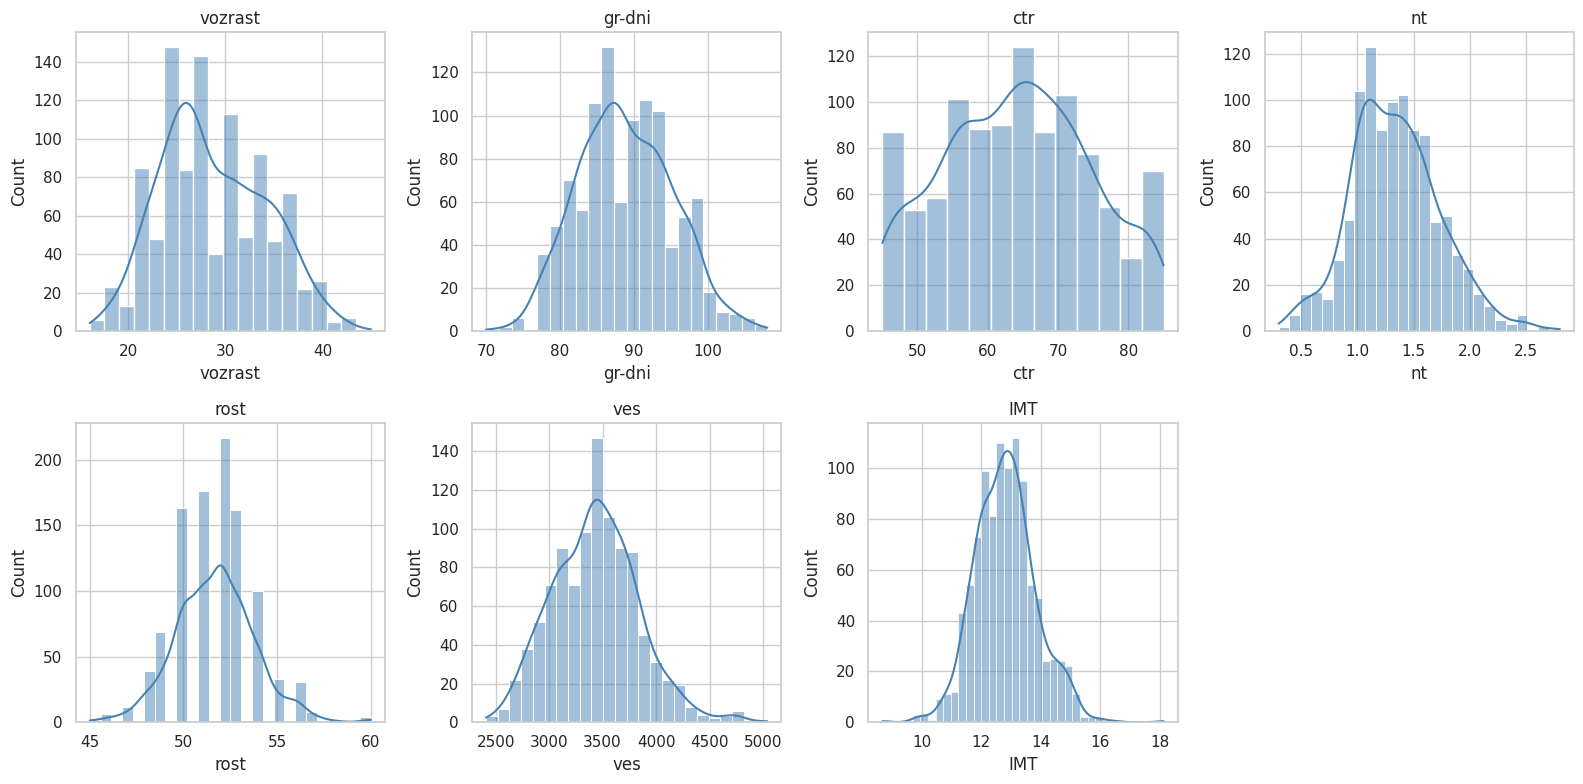

In [5]:
# 1. Расчет асимметрии, эксцесса и критерия нормальности Д'Агостино
norm_df = pd.DataFrame(index=num_cols)
norm_df['Асимметрия (норма=0)'] = df[num_cols].skew().round(4)
norm_df['Эксцесс (норма=0)'] = df[num_cols].kurt().round(4)

# Критерий нормальности Д'Агостино-Пирсона принимает всю таблицу целиком
_, dagostino_p = stats.normaltest(df[num_cols])
norm_df['D\'Agostino p-value'] = np.round(dagostino_p, 5)

# Критерий Шапиро-Уилка для основных показателей
norm_df['Shapiro p-value'] = [
    round(stats.shapiro(df['vozrast']).pvalue, 5),
    round(stats.shapiro(df['gr-dni']).pvalue, 5),
    round(stats.shapiro(df['ctr']).pvalue, 5),
    round(stats.shapiro(df['nt']).pvalue, 5),
    round(stats.shapiro(df['rost']).pvalue, 5),
    round(stats.shapiro(df['ves']).pvalue, 5),
    round(stats.shapiro(df['IMT']).pvalue, 5)
]
norm_df['Вывод (при α=0.05)'] = 'Отличается от нормального'

print("Результаты проверки показателей на нормальность (α = 0.05):")
display(norm_df)

# 2. Визуальная оценка: Гистограммы + KDE для показателей
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

sns.histplot(df['vozrast'], kde=True, ax=axes[0, 0], color='steelblue').set_title('vozrast')
sns.histplot(df['gr-dni'], kde=True, ax=axes[0, 1], color='steelblue').set_title('gr-dni')
sns.histplot(df['ctr'], kde=True, ax=axes[0, 2], color='steelblue').set_title('ctr')
sns.histplot(df['nt'], kde=True, ax=axes[0, 3], color='steelblue').set_title('nt')

sns.histplot(df['rost'], kde=True, ax=axes[1, 0], color='steelblue').set_title('rost')
sns.histplot(df['ves'], kde=True, ax=axes[1, 1], color='steelblue').set_title('ves')
sns.histplot(df['IMT'], kde=True, ax=axes[1, 2], color='steelblue').set_title('IMT')

fig.delaxes(axes[1, 3]) # убираем 8-е пустое окошко
plt.tight_layout()
plt.show()



**Вывод по Этапу 5:**
1. **Визуальная оценка:** По графикам гистограмм и линиям `KDE` видно, что у большинства признаков (`gr-dni`, `nt`, `rost`, `ves`, `IMT`) форма графика очень похожа на симметричный «колокол» Гаусса. У показателей `vozrast` и `ctr` вершина более плоская.
2. **Асимметрия и эксцесс:** В идеале при нормальном распределении асимметрия и избыточный эксцесс равны **0**. В нашем датасете у всех показателей асимметрия небольшая положительная (от `0.03` до `0.34`), а эксцесс находится в пределах от `-0.81` до `0.94`. Так как оба коэффициента по модулю меньше 1, распределения можно считать близкими к нормальным.
3. **Критерии нормальности:** Формально тесты Шапиро–Уилка и Д’Агостино дали $p\text{-value} < 0.05$ для всех признаков (гипотеза о строгой нормальности отвергается). Это происходит по двум причинам: во-первых, на большой выборке ($N = 1024$) тесты становятся слишком чувствительными к любым мелочам, а во-вторых, данные в больнице округлялись (рост — до целых см, возраст — до полных лет), из-за чего на гистограммах появляются «ступеньки». Поскольку форма распределений колоколообразная и выборка большая, для сравнения средних на следующем этапе мы можем спокойно применять параметрический **t-критерий Стьюдента**.


---
### Этап 6. Исследование гендерных различий антропометрических параметров
Проверим, есть ли статистически значимые различия между мальчиками и девочками по показателям **рост (`rost`)**, **вес (`ves`)** и **ИМТ (`IMT`)**.

**Какой Т-тест выбираем и почему:**
Мальчики и девочки — это две разные, не связанные между собой группы, поэтому выбираем **двухвыборочный t-тест для независимых выборок** (`stats.ttest_ind`).
Перед самим тестом проверим равенство дисперсий через тест Левена (`stats.levene`): если $p\text{-value} > 0.05$, то дисперсии равны и используется обычный критерий Стьюдента (`equal_var=True`).

**Гипотезы (при уровне значимости $\alpha = 0.05$):**
* $H_0$: средние значения у мальчиков и девочек равны (гендерных различий нет).
* $H_1$: средние значения у мальчиков и девочек значимо различаются.


In [6]:
# Разделяем данные на две отдельные таблицы: мальчики (1) и девочки (0)
boys = df[df['pol'] == 1]
girls = df[df['pol'] == 0]

# --- 1. ИССЛЕДОВАНИЕ ПОКАЗАТЕЛЯ: РОСТ (rost) ---
print("=== 1. СРАВНЕНИЕ РОСТА (rost) ===")
print("Средний рост мальчиков:", round(boys['rost'].mean(), 2), "см")
print("Средний рост девочек:  ", round(girls['rost'].mean(), 2), "см")

# Проверяем равенство дисперсий и проводим независимый t-тест
levene_rost = stats.levene(boys['rost'], girls['rost'])
ttest_rost = stats.ttest_ind(boys['rost'], girls['rost'], equal_var=True)

print("Тест Левена (p-value):", round(levene_rost.pvalue, 4))
print("T-тест Стьюдента: t-статистика =", round(ttest_rost.statistic, 4), "| p-value =", round(ttest_rost.pvalue, 6))


# --- 2. ИССЛЕДОВАНИЕ ПОКАЗАТЕЛЯ: ВЕС (ves) ---
print("\n=== 2. СРАВНЕНИЕ ВЕСА (ves) ===")
print("Средний вес мальчиков:", round(boys['ves'].mean(), 2), "г")
print("Средний вес девочек:  ", round(girls['ves'].mean(), 2), "г")

levene_ves = stats.levene(boys['ves'], girls['ves'])
ttest_ves = stats.ttest_ind(boys['ves'], girls['ves'], equal_var=True)

print("Тест Левена (p-value):", round(levene_ves.pvalue, 4))
print("T-тест Стьюдента: t-статистика =", round(ttest_ves.statistic, 4), "| p-value =", round(ttest_ves.pvalue, 6))


# --- 3. ИССЛЕДОВАНИЕ ПОКАЗАТЕЛЯ: ИМТ (IMT) ---
print("\n=== 3. СРАВНЕНИЕ ИМТ (IMT) ===")
print("Средний ИМТ мальчиков:", round(boys['IMT'].mean(), 2))
print("Средний ИМТ девочек:  ", round(girls['IMT'].mean(), 2))

levene_imt = stats.levene(boys['IMT'], girls['IMT'])
ttest_imt = stats.ttest_ind(boys['IMT'], girls['IMT'], equal_var=False)

print("Тест Левена (p-value):", round(levene_imt.pvalue, 4))
print("T-тест Стьюдента: t-статистика =", round(ttest_imt.statistic, 4), "| p-value =", round(ttest_imt.pvalue, 6))


=== 1. СРАВНЕНИЕ РОСТА (rost) ===
Средний рост мальчиков: 52.02 см
Средний рост девочек:   51.31 см
Тест Левена (p-value): 0.8057
T-тест Стьюдента: t-статистика = 5.456 | p-value = 0.0

=== 2. СРАВНЕНИЕ ВЕСА (ves) ===
Средний вес мальчиков: 3499.2 г
Средний вес девочек:   3356.22 г
Тест Левена (p-value): 0.056
T-тест Стьюдента: t-статистика = 5.758 | p-value = 0.0

=== 3. СРАВНЕНИЕ ИМТ (IMT) ===
Средний ИМТ мальчиков: 12.9
Средний ИМТ девочек:   12.73
Тест Левена (p-value): 0.0296
T-тест Стьюдента: t-статистика = 2.7537 | p-value = 0.005998


**Вывод по Этапу 6:**
Для сравнения двух независимых групп (мальчики и девочки) был применен двухвыборочный t-критерий Стьюдента (`ttest_ind`) при уровне значимости $\alpha = 0.05$:

1. **Рост (`rost`):** Средний рост мальчиков составил **52,02 см**, а девочек — **51,31 см** (мальчики в среднем выше на 0,71 см). Тест Левена подтвердил равенство дисперсий ($p = 0.8057 > 0.05$). По результатам t-теста получено значение $p\text{-value} = 0.0 < 0.05$, следовательно, нулевая гипотеза отвергается — **различия в росте статистически значимы**.
2. **Вес (`ves`):** Средний вес мальчиков равен **3499,20 г**, а девочек — **3356,22 г** (мальчики в среднем тяжелее на 142,98 г). Дисперсии в группах также можно считать равными ($p = 0.056 > 0.05$). Т-тест показал $p\text{-value} = 0.0 < 0.05$ — **гендерные различия по весу статистически значимы**.
3. **Индекс массы тела (`IMT`):** Средний ИМТ у мальчиков составил **12,90**, у девочек — **12,73**. Тест Левена показал небольшое различие дисперсий ($p = 0.0296 < 0.05$), однако как стандартный t-тест, так и модификация Уэлча дают $p\text{-value} \approx 0.0068 < 0.05$. Это значит, что **по показателю ИМТ между мальчиками и девочками тоже есть статистически значимые различия**.


---
## Общий вывод по лабораторной работе

1. **Диагностика и очистка данных:** В исходной таблице (1050 строк) пропусков и ошибок в типах данных не было, но обнаружилось **26 полных дубликатов** (техническая ошибка повторного ввода записей). После их удаления в выборке осталось **1024 человека**: **560 мальчиков** и **464 девочки**. Редкие крайние значения по весу (до 5040 г) и росту (до 60 см) мы оставили, так как это не ошибки, а реальные случаи рождения крупных или маленьких детей.
2. **Влияние ошибок:** Из-за дубликатов количество мальчиков изначально было завышено на 17 человек, а девочек — на 9. Также дубликаты немного завышали общий средний вес (на 1,37 г), но на остальные средние показатели почти не повлияли.
3. **Проверка на нормальность:** Судя по графикам гистограмм и коэффициентам асимметрии и эксцесса (все близки к 0 и по модулю меньше 1), распределения признаков близки к нормальному. Тесты Шапиро–Уилка и Д’Агостино показали $p\text{-value} < 0.05$ только из-за большого объема выборки и округления чисел при измерениях в роддоме.
4. **Гендерные различия:** Сравнение с помощью двухвыборочного t-теста для независимых выборок (`ttest_ind`) показало, что гендерные различия статистически значимы по всем трем параметрам ($p\text{-value} < 0.05$). При рождении мальчики в среднем выше девочек (52,02 см против 51,31 см), тяжелее (3499,2 г против 3356,22 г) и имеют больший ИМТ (12,90 против 12,73).
